# Spatial transcriptome reconstruction with vGEP

<div style="background: linear-gradient(135deg, #1a1a2e 0%, #16213e 50%, #0f3460 100%); color: white; padding: 1.2em 1.8em; border-radius: 10px; margin-bottom: 1em;">

<p style="margin: 0 0 0.2em 0; font-weight: 300; font-size: 0.95em; letter-spacing: 0.05em; opacity: 0.85;">BELLAICHE LAB — Institut Curie</p>
<p style="margin: 0; font-size: 0.82em; opacity: 0.7;">Adrien Leroy, Eric van Leen, Maria Balakireva, Lale Alpar, Fabian Gärtner, Rémi Pigache, Isabelle Gaugué, Stéphane Pelletier, Mehdi Ech-Chouini, Julien Delpierre, Stéphane Rigaud, Floris Bosveld, Lorette Noiret, Yohanns Bellaïche</p>
<p style="margin: 0.1em 0 0 0; font-size: 0.75em; opacity: 0.5;">April 2026</p>

</div>

In [Leroy, van Leen et al., Cell Reports (2026)](https://doi.org/10.5281/zenodo.19633285), once morphodynamic domains are defined ([notebook 01](01_morphodynamic_domains.ipynb)), we reconstruct a genome-wide spatial transcriptome to infer gene regulatory networks within each domain.

We profiled 12,187 cells from >160 nota at 15 hAPF by scRNA-seq. To map the epithelial cells back onto the tissue, we built a **reference atlas** of 24 gene expression patterns (fluorescent reporters and CRISPR knock-ins), averaged across animals on the same 40 µm bins as the morphometrics.

**vGEP** (Virtual Gene Expression Patterns) correlates each cell's profile with the atlas and averages the best-matching cells at each bin.

**Contents**

1. [Setup](#1.-Setup)
2. [Data loading](#2.-Data-loading)
3. [vGEP reconstruction](#3.-vGEP-reconstruction)

## 1. Setup

In [1]:
import os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# vGEP core functions
from vgep.spatial_transcriptome import generate_vgep
from vgep.optimization._vgep import optimize_transcriptome
from vgep.plotter import geometric

# Atlas gene lists and column-name fixes from the figure_spatial_transcriptome pipeline
MORPHODOMAINS_ROOT = Path("..").resolve()
sys.path.insert(0, str(MORPHODOMAINS_ROOT))
from scripts.figures.figure_spatial_transcriptome.preprocessing import (
    TRAINING_GENES,
    VALIDATION_GENES,
    NAME_CORRECTIONS,
    _load_single_cell,
    _load_and_filter_raw_counts,
)

# Data root: change this or set the MORPHODOMAINS_DATA env variable
# Default: the Zenodo archive root (contains data/), MORPHODOMAINS_ROOT.parents[1].
DATA_ROOT = Path(
    os.environ.get(
        "MORPHODOMAINS_DATA",
        str(MORPHODOMAINS_ROOT.parents[1]),
    )
)

SC_PATHS = {
    "SC_SINGLE_CELL_H5AD": DATA_ROOT / "data/single_cell/all_seurat_annotated_15_APF_wt.h5ad",
    "SC_RAW_COUNTS_CSV": DATA_ROOT / "data/single_cell/epi_RNA_counts.csv",
}
ATLAS_TXT = DATA_ROOT / "data/morphology/atlas_validation.txt"
MACROCHAETE = DATA_ROOT / "data/morphology/macrochaete.csv"
# Everything this notebook writes goes here, never into data/ where the figures read.
NOTEBOOK_OUTPUTS = Path("notebook_outputs") / "spatial_transcriptome"
NOTEBOOK_OUTPUTS.mkdir(parents=True, exist_ok=True)

## 2. Data loading

- **`raw_counts`** — 15 hAPF scRNA-seq counts (cells × genes), filtered as in the paper to epithelial notum cells
- **`atlas`** — the 24 training genes averaged over 491 bins (40 × 40 µm)
- **`geometry`** — bin coordinates (`x`, `y`), registered on the macrochaetae
- **`validation`** — 20 held-out genes (13 smiFISH, 7 protein reporters) used to score the reconstruction

In [2]:
raw_counts = _load_and_filter_raw_counts(SC_PATHS, _load_single_cell(SC_PATHS))
macrochaete = pd.read_csv(MACROCHAETE, header=None)

print(f"Raw counts: {raw_counts.shape[0]} cells x {raw_counts.shape[1]} genes")
raw_counts.head()

Raw counts: 7610 cells x 4312 genes


,Parp,Alg-2,Tim17b,CG41128,CG41099,Gfat1,CG40198,CG12581,beta-Man,DhpD,...,ND3,ND5,ND4,ND6,CYTB,ND1,28SrRNA-Psi:CR40596,28SrRNA-Psi:CR45851,SteXh:CG42398,CG7512
GAGCCTGGTTGACTAC_1,17.0,19.0,31.0,13.0,5.0,73.0,0.0,7.0,3.0,7.0,...,115.0,144.0,162.0,128.0,418.0,27.0,169.252029,399.229401,0.0,0.0
TACGGTAGTCCGGATC_1,14.0,13.0,31.0,16.0,4.0,40.0,0.0,1.0,6.0,3.0,...,168.0,196.0,204.0,178.0,576.0,32.0,232.479004,949.857605,0.0,0.0
TGATGGTCATCGATAC_1,10.0,14.0,42.0,22.0,2.0,84.0,0.0,10.0,2.0,3.0,...,30.0,65.0,63.0,91.0,312.0,14.0,183.659729,407.289856,0.0,0.0
GGAGAACCACCTGAAT_1,24.0,13.0,19.0,13.0,6.0,100.0,0.0,6.0,6.0,6.0,...,132.0,137.0,138.0,136.0,423.0,24.0,127.363441,385.354401,0.0,0.0
CATGCAATCTTCTTCC_1,21.0,18.0,29.0,26.0,4.0,79.0,2.0,6.0,6.0,5.0,...,121.0,142.0,142.0,148.0,383.0,21.0,145.440231,274.481506,0.0,0.0


In [3]:
# atlas_validation.txt holds the training genes, validation genes, the
# per-bin nota count, and bin coordinates (coordX/coordY). We load it once
# then split it into the three DataFrames the reconstruction methods expect.
atlas_full = pd.read_csv(ATLAS_TXT).rename(columns=NAME_CORRECTIONS)

geometry = atlas_full.iloc[:, -2:].rename({"coordX": "x", "coordY": "y"}, axis=1)
gene_data = atlas_full[TRAINING_GENES + VALIDATION_GENES + ["n_nota_gene"]]

# Keep only bins with at least one measured gene and ≥1 nota averaged
mask = (gene_data.fillna(0).sum(axis=1) > 0) & (gene_data["n_nota_gene"] > 0)
gene_data = gene_data.loc[mask]
geometry = geometry.loc[mask]

atlas = gene_data[TRAINING_GENES]
validation = gene_data[VALIDATION_GENES]

print(f"Atlas:      {atlas.shape[0]} bins x {atlas.shape[1]} training genes")
print(f"Validation: {validation.shape[0]} bins x {validation.shape[1]} genes")
print(f"Geometry:   {geometry.shape[0]} bins, columns {geometry.columns.tolist()}")
atlas.head()

Atlas:      491 bins x 24 training genes
Validation: 491 bins x 20 genes
Geometry:   491 bins, columns ['x', 'y']


,al,ara,B-H1,bi,Diap1,esg,exd,eyg,h,hh,...,sd,tsh,ush,sr,usp,wg,en,rpr,hid,Pax
563,0.797805,0.130159,0.044417,0.158417,0.278386,0.603898,0.270771,0.038714,0.450742,0.963424,...,0.379883,0.328959,0.973517,0.135825,0.808326,0.176245,0.633097,0.440950,0.288021,0.769429
564,0.746572,0.141862,0.043782,0.147125,0.326981,0.569397,0.306258,0.070253,0.495216,0.970757,...,0.377681,0.284477,0.959703,0.131303,0.810796,0.174530,0.721258,0.382375,0.316797,0.723138
565,0.696489,0.154034,0.042288,0.217598,0.259415,0.475580,0.366906,0.062424,0.459484,0.947532,...,0.376839,0.252872,0.900707,0.132850,0.762316,0.131148,0.804566,0.321650,0.484140,0.252336
566,0.652701,0.157116,0.042409,0.274687,0.242339,0.423464,0.451592,0.055736,0.468677,0.877934,...,0.375942,0.220846,0.809531,0.123557,0.745817,0.090709,0.894694,0.218566,0.393772,0.164785
567,0.611548,0.143127,0.048958,0.295902,0.278339,0.400208,0.560480,0.046109,0.466828,0.749048,...,0.348241,0.209125,0.772028,0.119982,0.800956,0.070922,0.906153,0.170217,0.162147,0.155499


A few atlas genes, plotted with `vgep.plotter.geometric`:

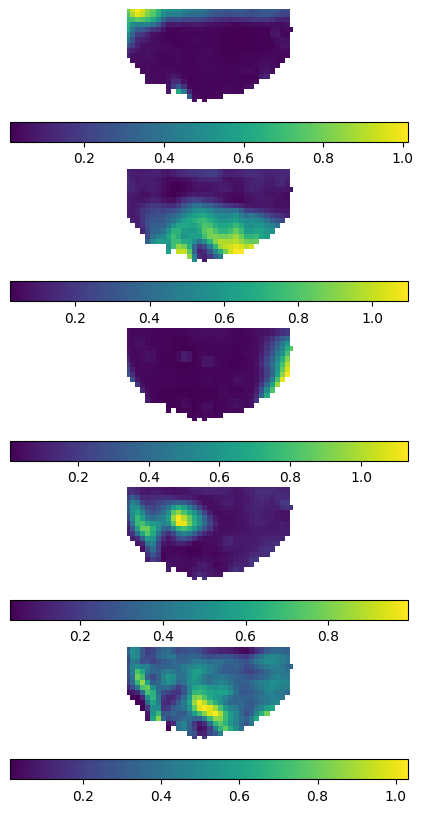

In [4]:
geometric(atlas, geometry=geometry, color=atlas.columns.tolist()[0:5])

In [5]:
# Convenience: define gene lists
training_genes = atlas.columns.tolist()
validation_genes = validation.columns.tolist()

print(f"{len(training_genes)} training genes, {len(validation_genes)} validation genes")

24 training genes, 20 validation genes


## 3. vGEP reconstruction

For each bin, vGEP correlates the atlas signature (24 training genes) with every cell, keeps the cells above a quantile cutoff $q$ (the only free parameter) and averages their full profiles:
1. **Normalise** — depth-normalise the counts $X$ (per 10,000 UMIs) → $X^{\text{scaled}}$; training genes $G_T$ are also log-transformed → $X^{\log}_T$.
2. **Correlate & filter** — $R_{k,i} = \text{corr}(A_{k,T}, X^{\log}_{i,T})$ for bin $k$ and cell $i$; values below quantile $q$ are zeroed → $R^{\text{map}}$.
3. **Reconstruct** — $P_{kj} = \frac{\sum_i R^{\text{map}}_{k,i} \, X^{\text{scaled}}_{i,j}}{\sum_i R^{\text{map}}_{k,i}}$

### Single reconstruction

`generate_vgep` runs one reconstruction and returns a `MuData`:
- `mdata['st']` — virtual expression (bins × genes)
- `mdata['sc']` — the single-cell data
- `mdata['meta']` — raw and filtered correlations, mapping mask

In [6]:
# Run a single vGEP reconstruction with a fixed cutoff
# cutoff: quantile threshold for keeping correlations (e.g. 0.9 = keep top 10% per bin)

CUTOFF = 0.9  # adjust based on your optimization results

mdata = generate_vgep(
    sc_data=raw_counts,
    atlas=atlas,
    geometry=geometry,
    cutoff=CUTOFF,
    validation=validation,  # optional: triggers accuracy assessment
)

print(mdata)

MuData object with n_obs × n_vars = 8101 × 16234
  3 modalities
    st:	491 x 4312
      obs:	'x', 'y'
      uns:	'training_genes', 'cutoff', 'morphological_marks', 'validation_genes', 'correlations_genes_training', 'correlations_genes_validation', 'results_recap'
    sc:	7610 x 4312
      layers:	'scaled_data'
    meta:	491 x 7610
      obs:	'x', 'y'
      layers:	'correlations_raw', 'mapped', 'normalized_correlation'


In [7]:
# Inspect the spatial transcriptome output
st = mdata["st"]
print("Virtual expression matrix (bins × genes):")
print(f"  {st.n_obs} bins, {st.n_vars} genes")

# If validation was provided, display accuracy summary
if "results_recap" in st.uns:
    print("\nValidation summary (Pearson r with ground-truth patterns):")
    print(st.uns["results_recap"])

Virtual expression matrix (bins × genes):
  491 bins, 4312 genes

Validation summary (Pearson r with ground-truth patterns):
            n genes      mean       min      q25%    median      q75%  \
Training         24  0.878351  0.556210  0.878262  0.902566  0.934460   
Validation       20  0.722027  0.565349  0.679441  0.727729  0.771941   

                 max  
Training    0.957486  
Validation  0.861831  


In [8]:
# Inspect mapping metadata
meta = mdata["meta"]
n_mapped = (meta.layers["mapped"].sum(axis=0) > 0).sum()
n_total = mdata["sc"].n_obs
print(f"Cells mapped to at least one bin: {n_mapped} / {n_total}")
print(f"Cells discarded: {n_total - n_mapped}")

Cells mapped to at least one bin: 7241 / 7610
Cells discarded: 369


### Cutoff optimisation

`optimize_transcriptome` sweeps the cutoff and keeps the value maximising mean + median Pearson r on the validation genes.

  0%|          | 0/59 [00:00<?, ?it/s]

  2%|▏         | 1/59 [00:00<00:16,  3.50it/s]

  3%|▎         | 2/59 [00:00<00:14,  3.83it/s]

  5%|▌         | 3/59 [00:00<00:13,  4.06it/s]

  7%|▋         | 4/59 [00:01<00:15,  3.65it/s]

  8%|▊         | 5/59 [00:01<00:14,  3.83it/s]

 10%|█         | 6/59 [00:01<00:13,  4.02it/s]

 12%|█▏        | 7/59 [00:01<00:12,  4.11it/s]

 14%|█▎        | 8/59 [00:02<00:12,  4.11it/s]

 15%|█▌        | 9/59 [00:02<00:12,  4.03it/s]

 17%|█▋        | 10/59 [00:02<00:11,  4.20it/s]

 19%|█▊        | 11/59 [00:02<00:11,  4.29it/s]

 20%|██        | 12/59 [00:02<00:10,  4.38it/s]

 22%|██▏       | 13/59 [00:03<00:10,  4.43it/s]

 24%|██▎       | 14/59 [00:03<00:10,  4.40it/s]

 25%|██▌       | 15/59 [00:03<00:09,  4.44it/s]

 27%|██▋       | 16/59 [00:03<00:09,  4.52it/s]

 29%|██▉       | 17/59 [00:04<00:09,  4.30it/s]

 31%|███       | 18/59 [00:04<00:09,  4.33it/s]

 32%|███▏      | 19/59 [00:04<00:09,  4.38it/s]

 34%|███▍      | 20/59 [00:04<00:08,  4.35it/s]

 36%|███▌      | 21/59 [00:04<00:08,  4.36it/s]

 37%|███▋      | 22/59 [00:05<00:08,  4.36it/s]

 39%|███▉      | 23/59 [00:05<00:08,  4.41it/s]

 41%|████      | 24/59 [00:05<00:07,  4.42it/s]

 42%|████▏     | 25/59 [00:05<00:08,  4.14it/s]

 44%|████▍     | 26/59 [00:06<00:08,  4.12it/s]

 46%|████▌     | 27/59 [00:06<00:07,  4.29it/s]

 47%|████▋     | 28/59 [00:06<00:07,  4.42it/s]

 49%|████▉     | 29/59 [00:06<00:06,  4.51it/s]

 51%|█████     | 30/59 [00:07<00:06,  4.57it/s]

 53%|█████▎    | 31/59 [00:07<00:06,  4.59it/s]

 54%|█████▍    | 32/59 [00:07<00:05,  4.61it/s]

 56%|█████▌    | 33/59 [00:07<00:05,  4.64it/s]

 58%|█████▊    | 34/59 [00:07<00:05,  4.63it/s]

 59%|█████▉    | 35/59 [00:08<00:05,  4.43it/s]

 61%|██████    | 36/59 [00:08<00:05,  4.45it/s]

 63%|██████▎   | 37/59 [00:08<00:04,  4.40it/s]

 64%|██████▍   | 38/59 [00:08<00:04,  4.45it/s]

 66%|██████▌   | 39/59 [00:09<00:04,  4.52it/s]

 68%|██████▊   | 40/59 [00:09<00:04,  4.57it/s]

 69%|██████▉   | 41/59 [00:09<00:03,  4.61it/s]

 71%|███████   | 42/59 [00:09<00:03,  4.62it/s]

 73%|███████▎  | 43/59 [00:09<00:03,  4.65it/s]

 75%|███████▍  | 44/59 [00:10<00:03,  4.49it/s]

 76%|███████▋  | 45/59 [00:10<00:03,  4.57it/s]

 78%|███████▊  | 46/59 [00:10<00:02,  4.59it/s]

 80%|███████▉  | 47/59 [00:10<00:02,  4.58it/s]

 81%|████████▏ | 48/59 [00:10<00:02,  4.58it/s]

 83%|████████▎ | 49/59 [00:11<00:02,  4.42it/s]

 85%|████████▍ | 50/59 [00:11<00:01,  4.52it/s]

 86%|████████▋ | 51/59 [00:11<00:01,  4.59it/s]

 88%|████████▊ | 52/59 [00:11<00:01,  4.61it/s]

 90%|████████▉ | 53/59 [00:12<00:01,  4.45it/s]

 92%|█████████▏| 54/59 [00:12<00:01,  4.54it/s]

 93%|█████████▎| 55/59 [00:12<00:00,  4.60it/s]

 95%|█████████▍| 56/59 [00:12<00:00,  4.66it/s]

 97%|█████████▋| 57/59 [00:12<00:00,  4.67it/s]

 98%|█████████▊| 58/59 [00:13<00:00,  4.71it/s]

100%|██████████| 59/59 [00:13<00:00,  4.66it/s]

100%|██████████| 59/59 [00:13<00:00,  4.41it/s]

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.




In [9]:
# Same cutoff grid as the figure_spatial_transcriptome production run.
list_cutoffs = np.arange(0.97, 0.999, 0.0005)

best_transcriptome = optimize_transcriptome(
    single_cells=raw_counts,
    atlas=atlas,
    geometry=geometry,
    validation=validation,
    list_cutoffs=list_cutoffs,
    output_path=str(NOTEBOOK_OUTPUTS),
    macrochaetae=macrochaete,
    plot_recap=True,
)

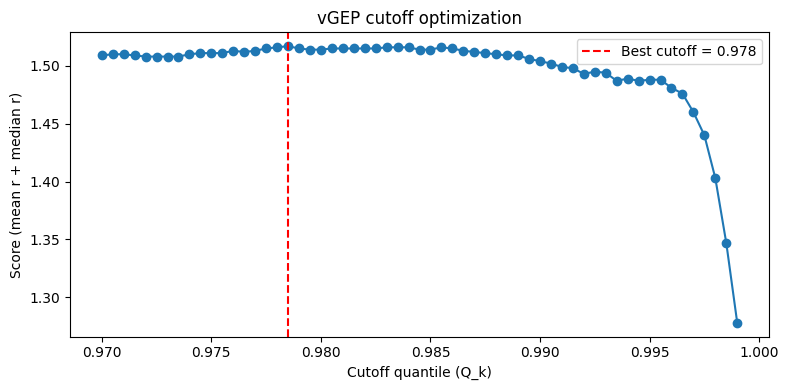

In [10]:
# Plot the optimization scores across cutoff values
results_df = pd.read_csv(NOTEBOOK_OUTPUTS / "results.csv", sep=";")
results_df["score"] = results_df["mean"].astype(float) + results_df["median"].astype(
    float
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(results_df["cutoff"].astype(float), results_df["score"], marker="o")
best_idx = results_df["score"].idxmax()
ax.axvline(
    results_df.loc[best_idx, "cutoff"],
    color="red",
    linestyle="--",
    label=f"Best cutoff = {results_df.loc[best_idx, 'cutoff']:.3f}",
)
ax.set_xlabel("Cutoff quantile (Q_k)")
ax.set_ylabel("Score (mean r + median r)")
ax.set_title("vGEP cutoff optimization")
ax.legend()
plt.tight_layout()
plt.show()